In [1]:

# 
# Run one simulation specifying 
# -> Radius of cylinder
# -> Discretization of the cylinder
# -> Distance of the circle of recievers
#
# Produces plots and .csv of RSME of the scattered and tital field

#===================================  IMP LIBRARIES =====================================#

import os
#os.environ['DRJIT_LIBLLVM_PATH'] = "/home/aizi0357/environments/sionna_v0/lib/libLLVM-20.so"
#os.environ["LD_LIBRARY_PATH"] = "$LD_LIBRARY_PATH:/home/aizi0357/environments/sionna_v0/lib/"

gpu_num = "" # Use "" to use the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import sionna

resolution = [480,320] # increase for higher quality of renderings

# Allows to exit cell execution in Jupyter
class ExitCell(Exception):
    def _render_traceback_(self):
        pass

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print("gpus:", gpus)
print(f"Using GPU {gpu_num}")
if gpu_num and gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)

tf.get_logger().setLevel('ERROR')

tf.random.set_seed(1) # Set global random seed for reproducibility

tf.config.run_functions_eagerly(True)

#%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import time

# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera


gpus: []
Using GPU 


In [2]:
#===================================  SETTING THE SCENE =====================================#

dtype = tf.complex128
rdtype = tf.float64


fc = 2e9  # Se cambio la frequenza il cylinder radio diventa 12.8 / 2 per lamda giusto ??????
lamda = 3e8 / fc

print("\n==== SIMULATION PARAMETERS ===")
print(f"fc: {fc}")
print(f"lamda: {lamda}")

cylinder_radius_lamda = 12.8
nu = 12

cylinder_radius = cylinder_radius_lamda * lamda
print(f"cylinder_radius: {cylinder_radius}")

scene = load_scene(f"./models/cylinder_{cylinder_radius_lamda}_lamda/cylinder_{nu}/cylinder_{nu}.xml", dtype)

scene.frequency = fc
scene.synthetic_array = True


#================================ SETTING RX and TX =========================================#

pol = 'HH'   

scene.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization=pol[0],
                             dtype=dtype)

scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization=pol[1],
                             dtype=dtype)


# =============================== PLACING TX ================================================== #

# Calcola a desnità di onda incidente e il modulo del campo incidente.
# Metti il TX che rispetti fronhoufer ma la potenza va normalizzta con la potenza incidente. 
# Questo per vedere come varia il campo scatterato al varire della distanza di osservazione.
# Cambia la potenza del trasmettitore in modo che il campo indidente sia sempre 1 V/m.

# Per la simulzione CST allunga il cilindro 

# Valuta il campo a distanza maggiori di 20 lamda per vedere se alte dicretizzazioni sono quele ottime 

D = cylinder_radius
tx_dist = 1000 * 2*((D*2)**2)/lamda + D # TX must be in Frahofer zone
tx_dist = 10e3



source_point = np.array([tx_dist, 0.0, 0.0])

tx = Transmitter(name="tx", position=source_point, dtype=dtype)

scene.remove("tx")
scene.add(tx)

coef = (4 * np.pi * tx_dist)




#================================ IMP DOUBLE EDGE DIFRACTION =========================================#

from sionna.rt.objects_geometry import ObjectsGeometry

obj_names = list(scene.objects.keys())

obj_geom = ObjectsGeometry(scene._solver_paths)
obj_geom.is_table_gfi = True
obj_geom.is_vertex_diffraction = True
obj_geom.is_double_diffraction = True
obj_geom.init_objects(obj_names, [None])

scene._solver_paths.vertex_diffraction.set_objects_geometry(obj_geom)
scene._solver_paths.double_diffraction.set_objects_geometry(obj_geom)

# tf.math.reduce_mean(scene._solver_paths._wedges_length) / lamda

RMSE_result = []


==== SIMULATION PARAMETERS ===
fc: 2000000000.0
lamda: 0.15
cylinder_radius: 1.92


2026-09-10 17:20:23 WARN wrk2 [PLYMesh] "cylinder_12.ply": attributes without postfix are not handled for now: attribute "stl" ignored.

num_edges: tf.Tensor(0, shape=(), dtype=int32)
num_wedges: 36
num vertices: 24


In [3]:
#=========================================== SIMULATION =====================================================#

#circle_radius = cylinder_radius + lamda*np.array([0.5, 1, 2, 10, 100, 1e3, 10e3])
circle_radius_i = cylinder_radius + 300



print("\n\n=== ELETTROMAGNETIC PARAMETERS ===")

r = circle_radius_i-cylinder_radius
 
    
#print(f"circle_of_recievers_radius: {circle_radius_i}")
print(f"Distance from the cylinder: {r/lamda} lamda")
print(f"Far field condition: {r} >> {lamda}")
print(f"Frahnoufer: {r} > {2* D**2 /lamda}")

# ============================== PLACING RX ==================================================== #
#num_points = 720*3
num_points = 16

theta_arr = np.linspace(0.0, 2*np.pi, num_points, endpoint=False)

def get_circle_points(theta_arr, p1, p2):
    res = np.zeros((len(theta_arr), 3))
    res[:, 0] = p1[0] * np.cos(theta_arr) + p2[0] * np.sin(theta_arr)
    res[:, 1] = p1[1] * np.cos(theta_arr) + p2[1] * np.sin(theta_arr)
    res[:, 2] = p1[2] * np.cos(theta_arr) + p2[2] * np.sin(theta_arr)

    return res

circle_p1 = np.array([1, 0, 0]) * circle_radius_i
circle_p2 = np.array([0, 1, 0])  * circle_radius_i
receive_points = get_circle_points(theta_arr, circle_p1, circle_p2)


for i in range(len(receive_points)):
    scene.remove(f"rx_{i}")
    rx = Receiver(name=f"rx_{i}", position=receive_points[i], dtype=dtype)
    scene.add(rx)



=== ELETTROMAGNETIC PARAMETERS ===
Distance from the cylinder: 2000.0 lamda
Far field condition: 300.0 >> 0.15
Frahnoufer: 300.0 > 49.152


Shadow region: [180.01325905069513° ,  180.01325905069513°]
[0.         0.39269908 0.78539816 1.17809725 1.57079633 1.96349541
 2.35619449 2.74889357 3.14159265 3.53429174 3.92699082 4.3196899
 4.71238898 5.10508806 5.49778714 5.89048623]
1.92
301.92


/tmp/ipykernel_19191/961745664.py:74: RuntimeWarning: divide by zero encountered in log10
  rmse_ee = rmse(20*np.log10(np.abs(an_total)), 20*np.log10(coef*receiver_amplitudes), forw_idxs) # RMSE
/home/matte/miniforge3/envs/ENV_TESI/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/matte/miniforge3/envs/ENV_TESI/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_19191/961745664.py:84: RuntimeWarning: divide by zero encountered in log10
  plt.plot(57.3*theta_arr, 20*np.log10(coef*receiver_amplitudes), label='Sionna-RT')
/tmp/ipykernel_19191/961745664.py:86: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.xlim([57.3*theta_arr[los_line_idx[0]],57.3*theta_arr[los_line_idx[1]]])


=> RMSE_forward: nan dB


<Figure size 640x480 with 0 Axes>

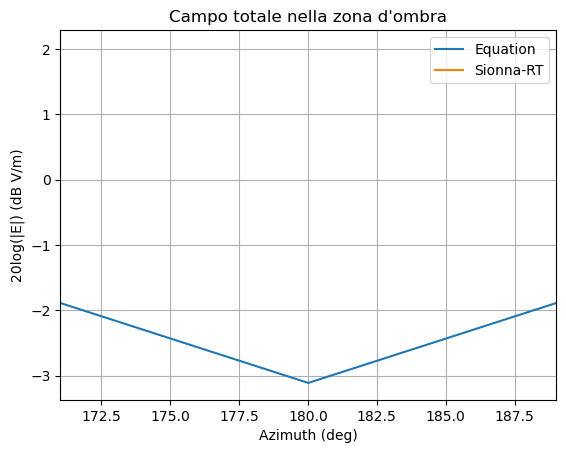

In [4]:
#========================================= SCATTERED FILED =================================================#


def get_field_los_full(tx_pos, rx_poses):
    # This fuction returns the field wich there would be without any obstacle

    dist = np.linalg.norm(tx_pos - rx_poses, axis=1)
    field = 1.0 / dist / (4 * 3.141592653589793) * lamda 
    return field

field_los_full = get_field_los_full(source_point, receive_points)

    
#== Calculating the SHADOW REGION
paths = scene.compute_paths(max_depth=1,
                            method="exhaustive",
                            num_samples=1e6,
                            los = True,
                            reflection = False,
                            diffraction = False,
                            vertex_diffraction = False)
    

a, tau = paths.cir()
path_amplitudes = a[0,:,0,0,0,:,0]
receiver_amplitudes_los = np.abs(np.sum(path_amplitudes, axis=1)) #/ lamda
    
los_line_idx = np.where(receiver_amplitudes_los <= 1e-9)[0][0], np.where(receiver_amplitudes_los <= 1e-9)[0][-1] #first and last index of the shadow region
#field_los_full = np.where(receiver_amplitudes_los <= 0.0, field_los_full, receiver_amplitudes_los) + 1e-6

print(f"Shadow region: [{57.3*theta_arr[los_line_idx[0]]}° ,  {57.3*theta_arr[los_line_idx[1]]}°]")

#== Calculating the ANALYTIC SCATTERED FILED (Plane wave incidence)
    
from sionna.rt.analytical_equations import cylinder_te_inc_scat_total, cylinder_tm_inc_scat_total

print(theta_arr)
print(cylinder_radius)
print(circle_radius_i)
    
if pol == 'HH':
    u_inc, an_scattering, an_total = cylinder_te_inc_scat_total(theta_arr, cylinder_radius, circle_radius_i, 2*np.pi / lamda, terms=512)
elif pol == 'VV':
    u_inc, an_scattering, an_total = cylinder_tm_inc_scat_total(theta_arr, cylinder_radius, circle_radius_i, 2*np.pi / lamda, terms=512)


 #== Calculating the TOTAL FIELD WITH DOUBLE-EDGE DIFFRACTION

paths = scene.compute_paths(max_depth=1,
                            method="exhaustive",
                            num_samples=1e6,
                            los = True,
                            reflection = False,
                            diffraction = True,
                            vertex_diffraction = False,
                            double_diffraction = False)
    
a, tau = paths.cir()
#a.shape   # [batch_size, num_rx, num_rx_ant, num_tx, num_tx_ant, max_num_paths, num_time_steps]
    
nans_bool = tf.math.is_nan(tf.math.real(a)) 
a = tf.where(nans_bool, tf.zeros_like(a), a)
    
path_amplitudes = a[0,:,0,0,0,:,0]
tmp1 = np.sum(path_amplitudes, axis=1)
receiver_amplitudes = np.abs(tmp1) / lamda

forw_idxs = np.arange(los_line_idx[0], los_line_idx[1]) # Forward scattering indexs

coef = (4 * np.pi * tx_dist)

def rmse(x, y, idxs):
    return np.sqrt(np.mean((x[idxs]-y[idxs])**2))
rmse_ee = rmse(20*np.log10(np.abs(an_total)), 20*np.log10(coef*receiver_amplitudes), forw_idxs) # RMSE
print(f"=> RMSE_forward: {rmse_ee} dB")

RMSE_result.append({"distance_in_lamda": r/lamda, "RMSE": rmse_ee}) 

    
plt.figure()
fig, ax = plt.subplots()
plt.title(rf"Campo totale nella zona d'ombra")
plt.plot(57.3*theta_arr, 20*np.log10(np.abs(an_total)), label='Equation')
plt.plot(57.3*theta_arr, 20*np.log10(coef*receiver_amplitudes), label='Sionna-RT')
plt.grid()
plt.xlim([57.3*theta_arr[los_line_idx[0]],57.3*theta_arr[los_line_idx[1]]])
plt.legend()
plt.xlabel("Azimuth (deg)")
plt.ylabel(f"20log(|E|) (dB V/m)")
plt.savefig(f".//total_field_{nu}_rx_{r/lamda}.png")

#df.to_csv(f"./risultati_full_{nu}_{cylinder_radius_lamda}.csv", index=False)
#print("Results of RMSE correctly exported")

In [5]:
scene.preview(paths=paths)

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, position=(0.0, 0.0, …